# ĐỒ ÁN PHÂN TÍCH DỮ LIỆU KINH DOANH SÁCH BÁN LẺ
## Xây dựng bộ dữ liệu, xử lý làm sạch, trực quan hóa và rút ra các ý nghĩa kinh doanh

---

### THÔNG TIN DỰ ÁN
* **Vị trí đảm nhiệm:** Data Analyst & Data Engineer
* **Ngôn ngữ & Thư viện:** Python (Pandas, NumPy, Matplotlib, Seaborn, Plotly, OpenPyXL)
* **Giai đoạn thực hiện:**
  1. Xây dựng bộ dữ liệu kinh doanh sách (mô phỏng sát thực tế thị trường Việt Nam)
  2. Quy trình xử lý dữ liệu (làm sạch, chuẩn hóa, xử lý ngoại lai, làm giàu đặc trưng)
  3. Trực quan hóa dữ liệu đa chiều (7 câu hỏi cốt lõi + biểu đồ chất lượng cao)
  4. Phân tích Insight chuyên sâu và Đề xuất chiến lược kinh doanh
* **Thời gian dữ liệu:** 24 tháng liên tục (01/2024 - 12/2025)


In [1]:
# Thiết lập môi trường và nạp các thư viện phân tích
import os
import sys
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Cấu hình hiển thị font tiếng Việt và giao diện biểu đồ
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans', 'Tahoma']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({'font.size': 11, 'figure.titlesize': 13})
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Đã tải xong toàn bộ thư viện cần thiết!")


Đã tải xong toàn bộ thư viện cần thiết!


---
# GIAI ĐOẠN 1: XÂY DỰNG BỘ DỮ LIỆU KINH DOANH SÁCH

### 1.1. Lựa chọn nguồn dữ liệu & Phương pháp xây dựng
* **Khảo sát thực tế:** Các nền tảng thương mại điện tử công khai tại Việt Nam (Tiki, Fahasa, Shopee) áp dụng hệ thống bảo mật Cloudflare / Captcha khắt khe, đồng thời không công khai dữ liệu lịch sử giao dịch bán hàng (chỉ hiển thị lượng bán lũy kế tích lũy, không có thông tin thời gian thực theo từng đơn hàng).
* **Phương án triển khai:** Áp dụng phương án **Mô phỏng thực tế có kiểm soát (Synthetic Real-world Simulation)** với seed ngẫu nhiên cố định (`seed=42`) để đảm bảo tính tái lập 100%.
* **Đặc tính bộ dữ liệu:**
  - Quy mô: 6,660 dòng giao dịch bán lẻ thô.
  - Phủ 10 thể loại sách phổ biến nhất tại Việt Nam (Kỹ năng sống, Văn học, Kinh tế, Thiếu nhi...).
  - Dữ liệu trải dài 24 tháng (2024 - 2025).
  - Phản ánh đúng logic kinh tế: giảm giá kích cầu, mùa vụ tựu trường (T8-T9) và Mega Sale (T11-T12), kênh bán đa dạng (Shopee, TikTok, Tiki, Offline, Website).
  - Cố ý đưa vào các lỗi thực tế: trùng lặp, thiếu giá trị, lỗi định dạng tiền tệ, ngoại lai nhập liệu.


In [2]:
# Nạp dữ liệu thô ban đầu
raw_data_path = "../data/raw/book_sales_raw.csv"
if not os.path.exists(raw_data_path):
    # Nếu chạy từ thư mục gốc
    raw_data_path = "data/raw/book_sales_raw.csv"

df_raw = pd.read_csv(raw_data_path)
print(f"Kích thước dữ liệu thô: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")
df_raw.head(5)


Kích thước dữ liệu thô: 6660 dòng, 14 cột


,ma_sach,ten_sach,tac_gia,the_loai,nha_xuat_ban,nam_xuat_ban,gia_goc,gia_ban,phan_tram_giam_gia,so_luong_da_ban,diem_danh_gia,so_luot_danh_gia,ngay_ban,kenh_ban
0,BK00748,Tự Học 2000 Từ Vựng Tiếng Anh (Tập 6),Mai Lan Hương,Giáo dục - Ngoại ngữ,NXB Kim Đồng,2022.00,230000,138000,40.00,7,4.90,57,2025-01-22,Tiki Trading
1,BK00212,Cánh Đồng Bất Tận (Tập 10),George Orwell,Văn học,NXB Thế Giới,2019.00,254000,165000,35.00,9,3.40,50,2024-02-29,Shopee Mall
2,BK00033,Thay Đổi Tí Hon Hiệu Quả Bất Ngờ (Tập 5),Mark Manson,Kỹ năng sống,NXB Kim Đồng,2015.00,117000,94000,20.00,6,4.30,37,2025-05-03,Shopee Mall
3,BK00136,Truyện Kiều (Tập 2),Franz Kafka,Văn học,NXB Hội Nhà Văn,2018.00,159000,119000,25.00,9,3.60,18,2024-02-18,Shopee Mall
4,BK00281,Tâm Lý Học Về Tiền (Tập 6),Peter Drucker,Kinh tế - Quản trị,NXB Hội Nhà Văn,2019.00,87000,65000,25.00,28,4.60,31,2025-11-28,Shopee Mall


In [3]:
# Khảo sát kiểu dữ liệu, số lượng trùng lặp và giá trị khuyết thiếu ban đầu
print("=== THÔNG TIN KIỂU DỮ LIỆU BAN ĐẦU ===")
print(df_raw.dtypes)

print("\n=== SỐ LƯỢNG TRÙNG LẶP BAN ĐẦU ===")
num_duplicates_raw = df_raw.duplicated().sum()
print(f"Số dòng trùng lặp hoàn toàn: {num_duplicates_raw} dòng ({num_duplicates_raw/len(df_raw)*100:.2f}%)")

print("\n=== SỐ LƯỢNG GIÁ TRỊ THIẾU THEO CỘT ===")
missing_summary = df_raw.isna().sum()
missing_summary = missing_summary[missing_summary > 0]
for col, val in missing_summary.items():
    print(f"- Cột '{col}': {val} ô thiếu ({val/len(df_raw)*100:.2f}%)")


=== THÔNG TIN KIỂU DỮ LIỆU BAN ĐẦU ===
ma_sach                   str
ten_sach                  str
tac_gia                   str
the_loai                  str
nha_xuat_ban              str
nam_xuat_ban          float64
gia_goc                 int64
gia_ban                   str
phan_tram_giam_gia    float64
so_luong_da_ban         int64
diem_danh_gia         float64
so_luot_danh_gia        int64
ngay_ban                  str
kenh_ban                  str
dtype: object

=== SỐ LƯỢNG TRÙNG LẶP BAN ĐẦU ===
Số dòng trùng lặp hoàn toàn: 117 dòng (1.76%)

=== SỐ LƯỢNG GIÁ TRỊ THIẾU THEO CỘT ===
- Cột 'tac_gia': 45 ô thiếu (0.68%)
- Cột 'nha_xuat_ban': 130 ô thiếu (1.95%)
- Cột 'nam_xuat_ban': 85 ô thiếu (1.28%)
- Cột 'diem_danh_gia': 110 ô thiếu (1.65%)


---
# GIAI ĐOẠN 2: QUY TRÌNH XỬ LÝ & CHUẨN HÓA DỮ LIỆU (DATA CLEANING)

Quy trình xử lý dữ liệu được thiết kế bài bản theo từng bước và ghi nhận số liệu **Trước (Before)** và **Sau (After)**:
1. **Loại bỏ trùng lặp hoàn toàn:** Xóa bỏ các bản ghi ghi nhận trùng lặp do lỗi truyền tải hệ thống.
2. **Chuẩn hóa định dạng giá bán & phần trăm giảm giá:** Tách lọc chuỗi ký tự (`"VNĐ"`, dấu phẩy), khôi phục các giá bán âm hoặc bằng 0 bằng công thức `gia_goc * (1 - giam_gia)`.
3. **Chuẩn hóa chuỗi văn bản (String Cleaning):** Đồng nhất Title Case, loại bỏ khoảng trắng thừa đầu cuối và ở giữa cho Thể loại, Nhà xuất bản, Tên sách.
4. **Xử lý giá trị thiếu (Missing Values):** Điền `tac_gia` khuyết thành `"Không rõ tác giả"`, `nha_xuat_ban` thành `"NXB Khác"`, điền `nam_xuat_ban` bằng trung vị theo thể loại, điền `diem_danh_gia` bằng trung bình theo thể loại.
5. **Phát hiện và xử lý ngoại lai (Outliers):** Lọc bỏ số lượng bán âm (< 1) và ngoại lai nhập liệu ảo (> 150 cuốn). Khử trùng lặp phát sinh.
6. **Làm giàu đặc trưng (Feature Engineering):** Tạo cột `doanh_thu`, `phan_khuc_gia`, thời gian (`thang_ban`, `quy_ban`, `nam_ban`, `thang_nam`, `thu_trong_tuan`), và `nhom_danh_gia`.


In [4]:
# Thực hiện làm sạch dữ liệu
df = df_raw.copy()
metrics_log = []

# Bước 1: Ban đầu
metrics_log.append({
    "Bước xử lý": "1. Dữ liệu thô ban đầu",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Nạp file CSV thô ban đầu"
})

# Bước 2: Loại bỏ trùng lặp
df.drop_duplicates(inplace=True)
metrics_log.append({
    "Bước xử lý": "2. Loại bỏ trùng lặp",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Loại bỏ các dòng trùng lặp 100%"
})

# Bước 3: Chuẩn hóa giá bán
def parse_price(val):
    if pd.isna(val): return np.nan
    if isinstance(val, (int, float)): return float(val)
    clean_str = re.sub(r"[^\d.-]", "", str(val))
    try: return float(clean_str)
    except: return np.nan

df["gia_ban_num"] = df["gia_ban"].apply(parse_price)
invalid_mask = (df["gia_ban_num"] <= 0) | (df["gia_ban_num"].isna())
df.loc[invalid_mask, "gia_ban_num"] = (
    df.loc[invalid_mask, "gia_goc"] * (1 - df.loc[invalid_mask, "phan_tram_giam_gia"] / 100.0)
).round(-3)
df["gia_ban"] = df["gia_ban_num"].astype(int)
df.drop(columns=["gia_ban_num"], inplace=True)
df["phan_tram_giam_gia"] = np.maximum(0.0, np.round((1.0 - df["gia_ban"] / df["gia_goc"]) * 100.0, 1))

metrics_log.append({
    "Bước xử lý": "3. Chuẩn hóa giá bán",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Chuyển về số nguyên VNĐ, sửa giá âm/0"
})

# Bước 4: Chuẩn hóa văn bản
genre_mapping = {
    "kỹ năng sống": "Kỹ năng sống", "văn học": "Văn học", "kinh tế - quản trị": "Kinh tế - Quản trị",
    "thiếu nhi": "Thiếu nhi", "tâm lý học": "Tâm lý học", "khoa học công nghệ": "Khoa học công nghệ",
    "giáo dục - ngoại ngữ": "Giáo dục - Ngoại ngữ", "lịch sử - triết học": "Lịch sử - Triết học",
    "truyện tranh - manga": "Truyện tranh - Manga", "nuôi dạy con": "Nuôi dạy con"
}

def clean_genre(val):
    if pd.isna(val): return "Khác"
    s = re.sub(r"\s+", " ", str(val).strip().lower())
    return genre_mapping.get(s, str(val).strip().title())

df["the_loai"] = df["the_loai"].apply(clean_genre)

def clean_pub(val):
    if pd.isna(val): return "NXB Khác"
    s = re.sub(r"\s+", " ", str(val).strip()).lower()
    if "kim đồng" in s: return "NXB Kim Đồng"
    elif "trẻ" in s: return "NXB Trẻ"
    elif "hội nhà văn" in s: return "NXB Hội Nhà Văn"
    elif "phụ nữ" in s: return "NXB Phụ Nữ"
    elif "tổng hợp" in s: return "NXB Tổng Hợp TP.HCM"
    elif "thế giới" in s: return "NXB Thế Giới"
    elif "lao động" in s: return "NXB Lao Động"
    elif "dân trí" in s: return "NXB Dân Trí"
    return str(val).strip().title()

df["nha_xuat_ban"] = df["nha_xuat_ban"].apply(clean_pub)
df["tac_gia"] = df["tac_gia"].fillna("Không rõ tác giả").apply(lambda x: re.sub(r"\s+", " ", str(x).strip()))
df["ten_sach"] = df["ten_sach"].apply(lambda x: re.sub(r"\s+", " ", str(x).strip()))

metrics_log.append({
    "Bước xử lý": "4. Chuẩn hóa chuỗi văn bản",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Xóa khoảng trắng thừa, chuẩn hóa danh mục NXB/Thể loại"
})

# Bước 5: Điền giá trị thiếu
median_years = df.groupby("the_loai")["nam_xuat_ban"].transform("median")
df["nam_xuat_ban"] = df["nam_xuat_ban"].fillna(median_years).fillna(2020).astype(int)

mean_ratings = df.groupby("the_loai")["diem_danh_gia"].transform("mean")
df["diem_danh_gia"] = df["diem_danh_gia"].fillna(mean_ratings).fillna(4.2).round(1)

metrics_log.append({
    "Bước xử lý": "5. Điền giá trị khuyết thiếu",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Điền trung vị/trung bình nhóm, đạt 100% không khuyết"
})

# Bước 6: Xử lý ngoại lai & khử trùng lặp
invalid_qty_mask = df["so_luong_da_ban"] < 1
extreme_qty_mask = df["so_luong_da_ban"] > 150
df = df[~invalid_qty_mask & ~extreme_qty_mask].copy()
df.drop_duplicates(inplace=True)

metrics_log.append({
    "Bước xử lý": "6. Xử lý ngoại lai & Khử trùng",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Loại bỏ số lượng âm & ảo >150 cuốn, khử trùng"
})

# Bước 7: Feature Engineering
df["doanh_thu"] = df["gia_ban"] * df["so_luong_da_ban"]
df["phan_khuc_gia"] = pd.cut(
    df["gia_ban"],
    bins=[-1, 80000, 200000, 1000000],
    labels=["Giá rẻ (< 80k)", "Trung bình (80k - 200k)", "Cao cấp (> 200k)"]
)
df["ngay_ban"] = pd.to_datetime(df["ngay_ban"])
df["thang_ban"] = df["ngay_ban"].dt.month
df["quy_ban"] = "Q" + df["ngay_ban"].dt.quarter.astype(str)
df["nam_ban"] = df["ngay_ban"].dt.year
df["thang_nam"] = df["ngay_ban"].dt.strftime("%Y-%m")
weekday_map = {0: "Thứ Hai", 1: "Thứ Ba", 2: "Thứ Tư", 3: "Thứ Năm", 4: "Thứ Sáu", 5: "Thứ Bảy", 6: "Chủ Nhật"}
df["thu_trong_tuan"] = df["ngay_ban"].dt.weekday.map(weekday_map)

df["nhom_danh_gia"] = pd.cut(
    df["diem_danh_gia"],
    bins=[0, 3.0, 4.0, 4.5, 5.0],
    labels=["Thấp (< 3.0)", "Trung bình (3.0 - < 4.0)", "Tốt (4.0 - < 4.5)", "Xuất sắc (>= 4.5)"]
)

metrics_log.append({
    "Bước xử lý": "7. Làm giàu đặc trưng",
    "Số dòng": len(df), "Số cột": df.shape[1],
    "Số trùng lặp": int(df.duplicated().sum()), "Số ô thiếu": int(df.isna().sum().sum()),
    "Mô tả": "Tạo doanh_thu, phan_khuc_gia, thời gian, nhom_danh_gia"
})

# Bảng tổng kết Before & After
df_metrics = pd.DataFrame(metrics_log)
print("=== BẢNG ĐỐI SOÁT TRƯỚC VÀ SAU CÁC BƯỚC XỬ LÝ DỮ LIỆU ===")
df_metrics


=== BẢNG ĐỐI SOÁT TRƯỚC VÀ SAU CÁC BƯỚC XỬ LÝ DỮ LIỆU ===


,Bước xử lý,Số dòng,Số cột,Số trùng lặp,Số ô thiếu,Mô tả
0,1. Dữ liệu thô ban đầu,6660,14,117,370,Nạp file CSV thô ban đầu
1,2. Loại bỏ trùng lặp,6543,14,0,370,Loại bỏ các dòng trùng lặp 100%
2,3. Chuẩn hóa giá bán,6543,14,6,370,"Chuyển về số nguyên VNĐ, sửa giá âm/0"
3,4. Chuẩn hóa chuỗi văn bản,6543,14,25,195,"Xóa khoảng trắng thừa, chuẩn hóa danh mục NXB/..."
4,5. Điền giá trị khuyết thiếu,6543,14,27,0,"Điền trung vị/trung bình nhóm, đạt 100% không ..."
5,6. Xử lý ngoại lai & Khử trùng,6501,14,0,0,"Loại bỏ số lượng âm & ảo >150 cuốn, khử trùng"
6,7. Làm giàu đặc trưng,6501,22,0,0,"Tạo doanh_thu, phan_khuc_gia, thời gian, nhom_..."


---
# GIAI ĐOẠN 3: TRỰC QUAN HÓA DỮ LIỆU & PHÂN TÍCH

Chúng ta tiến hành trả lời 7 câu hỏi kinh doanh cốt lõi qua hệ thống đồ thị chuyên sâu:
1. **Câu hỏi 1:** Thể loại nào bán chạy nhất / Doanh thu cao nhất?
2. **Câu hỏi 2:** Top 10 tựa sách, tác giả và nhà xuất bản nổi bật nhất?
3. **Câu hỏi 3:** Biến động doanh thu và sản lượng theo thời gian (tháng/quý)?
4. **Câu hỏi 4:** Giá bán và tỷ lệ giảm giá ảnh hưởng thế nào đến lượng bán?
5. **Câu hỏi 5:** Điểm đánh giá cao có đồng nghĩa với sản lượng bán nhiều hơn?
6. **Câu hỏi 6:** Ma trận tương quan đa biến (Correlation Heatmap)?
7. **Câu hỏi 7:** Cơ cấu doanh thu theo Phân khúc giá và Kênh phân phối?


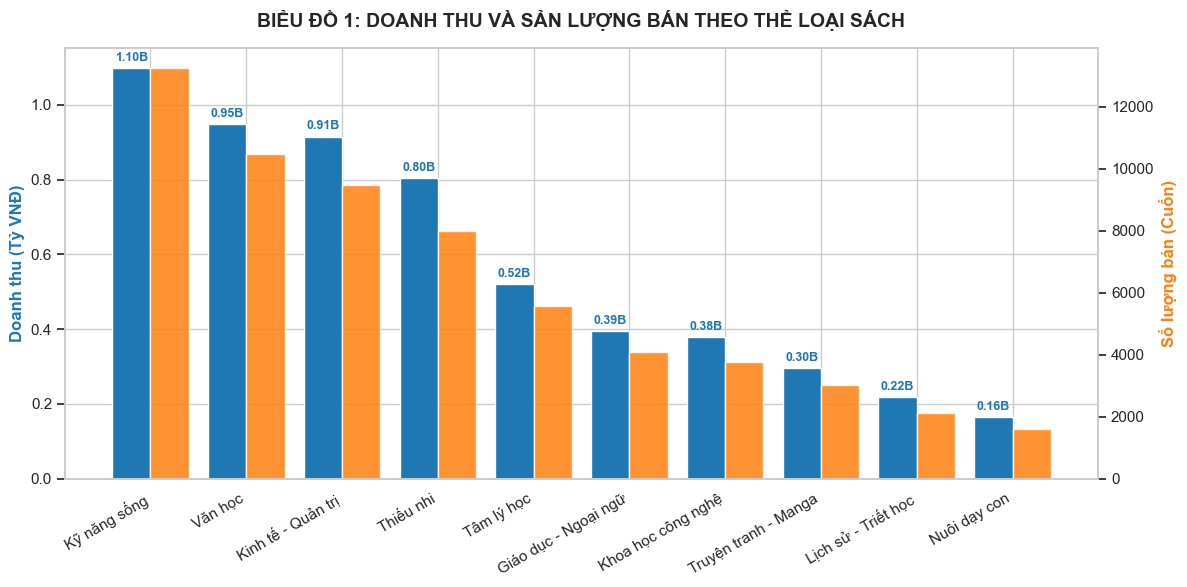

In [5]:
# 1. Thể loại nào bán chạy nhất & Doanh thu cao nhất?
genre_summary = df.groupby("the_loai").agg(
    doanh_thu=("doanh_thu", "sum"),
    so_luong=("so_luong_da_ban", "sum")
).reset_index()
genre_summary["doanh_thu_ty"] = genre_summary["doanh_thu"] / 1e9
genre_summary.sort_values(by="doanh_thu_ty", ascending=False, inplace=True)

fig, ax1 = plt.subplots(figsize=(12, 6))
x = np.arange(len(genre_summary))
width = 0.4

bars1 = ax1.bar(x - width/2, genre_summary["doanh_thu_ty"], width, label="Doanh thu (Tỷ VNĐ)", color="#1f77b4")
ax1.set_ylabel("Doanh thu (Tỷ VNĐ)", color="#1f77b4", fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(genre_summary["the_loai"], rotation=30, ha="right")

ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, genre_summary["so_luong"], width, label="Số lượng bán (Cuốn)", color="#ff7f0e", alpha=0.85)
ax2.set_ylabel("Số lượng bán (Cuốn)", color="#ff7f0e", fontweight="bold")
ax2.grid(False)

for b in bars1:
    h = b.get_height()
    ax1.annotate(f'{h:.2f}B', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color="#1f77b4")

plt.title("BIỂU ĐỒ 1: DOANH THU VÀ SẢN LƯỢNG BÁN THEO THỂ LOẠI SÁCH", fontsize=14, fontweight="bold", pad=15)
fig.tight_layout()
plt.show()


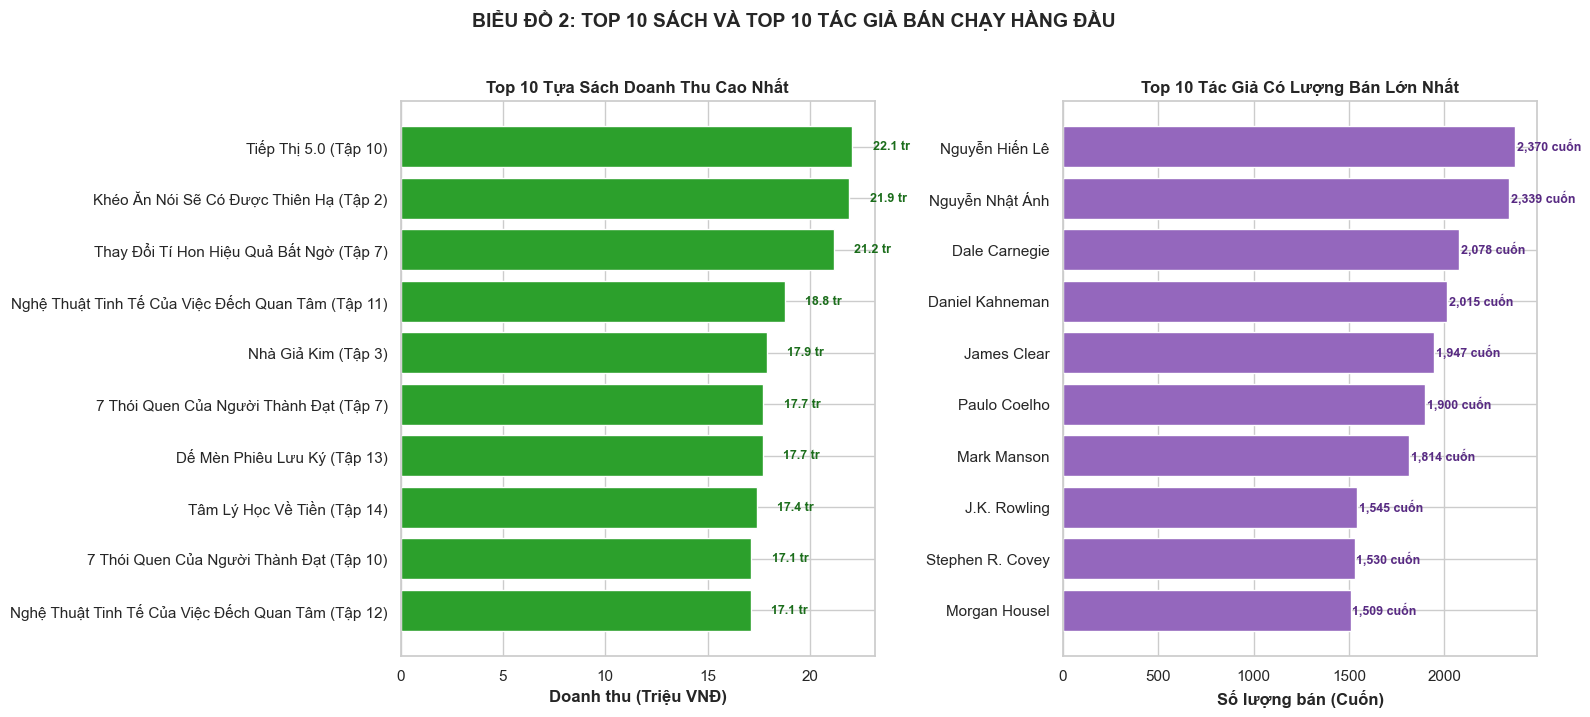

In [6]:
# 2. Top 10 Sách & Top 10 Tác giả nổi bật
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top 10 Sách theo doanh thu
top_books = df.groupby("ten_sach")["doanh_thu"].sum().reset_index()
top_books["doanh_thu_trieu"] = top_books["doanh_thu"] / 1e6
top_books = top_books.sort_values(by="doanh_thu_trieu", ascending=True).tail(10)

axes[0].barh(top_books["ten_sach"], top_books["doanh_thu_trieu"], color="#2ca02c")
axes[0].set_title("Top 10 Tựa Sách Doanh Thu Cao Nhất", fontweight="bold", fontsize=12)
axes[0].set_xlabel("Doanh thu (Triệu VNĐ)", fontweight="bold")
for i, v in enumerate(top_books["doanh_thu_trieu"]):
    axes[0].text(v + 1, i, f"{v:.1f} tr", va='center', fontsize=9, fontweight='bold', color="#1b6d1b")

# Top 10 Tác giả theo số lượng
top_authors = df[df["tac_gia"] != "Không rõ tác giả"].groupby("tac_gia")["so_luong_da_ban"].sum().reset_index()
top_authors = top_authors.sort_values(by="so_luong_da_ban", ascending=True).tail(10)

axes[1].barh(top_authors["tac_gia"], top_authors["so_luong_da_ban"], color="#9467bd")
axes[1].set_title("Top 10 Tác Giả Có Lượng Bán Lớn Nhất", fontweight="bold", fontsize=12)
axes[1].set_xlabel("Số lượng bán (Cuốn)", fontweight="bold")
for i, v in enumerate(top_authors["so_luong_da_ban"]):
    axes[1].text(v + 10, i, f"{v:,} cuốn", va='center', fontsize=9, fontweight='bold', color="#582a83")

plt.suptitle("BIỂU ĐỒ 2: TOP 10 SÁCH VÀ TOP 10 TÁC GIẢ BÁN CHẠY HÀNG ĐẦU", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()


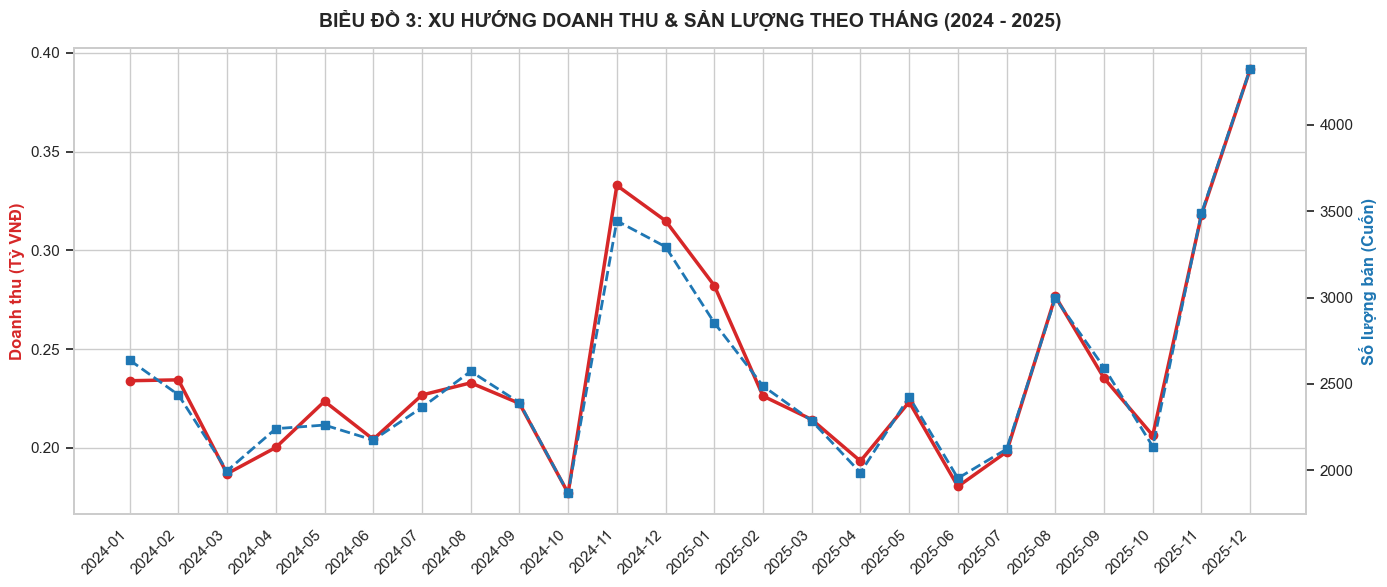

In [7]:
# 3. Biến động Doanh thu & Sản lượng theo thời gian (24 tháng)
monthly_trend = df.groupby("thang_nam").agg(
    doanh_thu=("doanh_thu", "sum"),
    so_luong=("so_luong_da_ban", "sum")
).reset_index()
monthly_trend["doanh_thu_ty"] = monthly_trend["doanh_thu"] / 1e9

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(monthly_trend["thang_nam"], monthly_trend["doanh_thu_ty"], marker='o', color="#d62728", linewidth=2.5, label="Doanh thu (Tỷ VNĐ)")
ax1.set_ylabel("Doanh thu (Tỷ VNĐ)", color="#d62728", fontweight="bold")
ax1.set_xticks(range(len(monthly_trend)))
ax1.set_xticklabels(monthly_trend["thang_nam"], rotation=45, ha="right")

ax2 = ax1.twinx()
ax2.plot(monthly_trend["thang_nam"], monthly_trend["so_luong"], marker='s', linestyle="--", color="#1f77b4", linewidth=2, label="Số lượng bán (Cuốn)")
ax2.set_ylabel("Số lượng bán (Cuốn)", color="#1f77b4", fontweight="bold")
ax2.grid(False)

plt.title("BIỂU ĐỒ 3: XU HƯỚNG DOANH THU & SẢN LƯỢNG THEO THÁNG (2024 - 2025)", fontsize=14, fontweight="bold", pad=15)
fig.tight_layout()
plt.show()


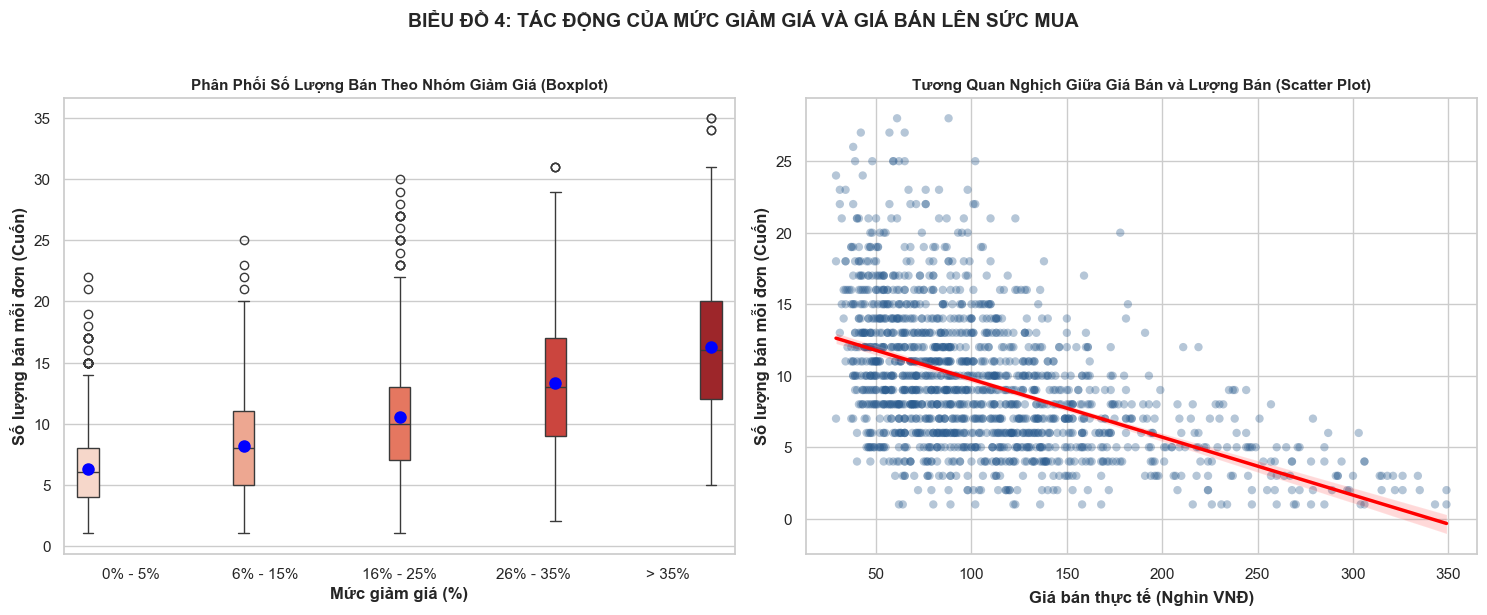

In [8]:
# 4. Tác động của Mức giảm giá & Giá bán lên Lượng bán
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

df["nhom_giam_gia"] = pd.cut(
    df["phan_tram_giam_gia"],
    bins=[-1, 5, 15, 25, 35, 100],
    labels=["0% - 5%", "6% - 15%", "16% - 25%", "26% - 35%", "> 35%"]
)

sns.boxplot(data=df, x="nhom_giam_gia", y="so_luong_da_ban", ax=axes[0], palette="Reds", hue="nhom_giam_gia", legend=False, showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"blue", "markeredgecolor":"blue", "markersize":"8"})
axes[0].set_title("Phân Phối Số Lượng Bán Theo Nhóm Giảm Giá (Boxplot)", fontweight="bold", fontsize=11)
axes[0].set_xlabel("Mức giảm giá (%)", fontweight="bold")
axes[0].set_ylabel("Số lượng bán mỗi đơn (Cuốn)", fontweight="bold")

sample_df = df.sample(n=min(1500, len(df)), random_state=42)
axes[1].scatter(sample_df["gia_ban"] / 1000, sample_df["so_luong_da_ban"], alpha=0.35, color="#2b5c8f", edgecolors="none")
sns.regplot(data=sample_df, x=sample_df["gia_ban"]/1000, y="so_luong_da_ban", ax=axes[1], scatter=False, color="red", line_kws={"linewidth": 2.5})
axes[1].set_title("Tương Quan Nghịch Giữa Giá Bán và Lượng Bán (Scatter Plot)", fontweight="bold", fontsize=11)
axes[1].set_xlabel("Giá bán thực tế (Nghìn VNĐ)", fontweight="bold")
axes[1].set_ylabel("Số lượng bán mỗi đơn (Cuốn)", fontweight="bold")

plt.suptitle("BIỂU ĐỒ 4: TÁC ĐỘNG CỦA MỨC GIẢM GIÁ VÀ GIÁ BÁN LÊN SỨC MUA", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()


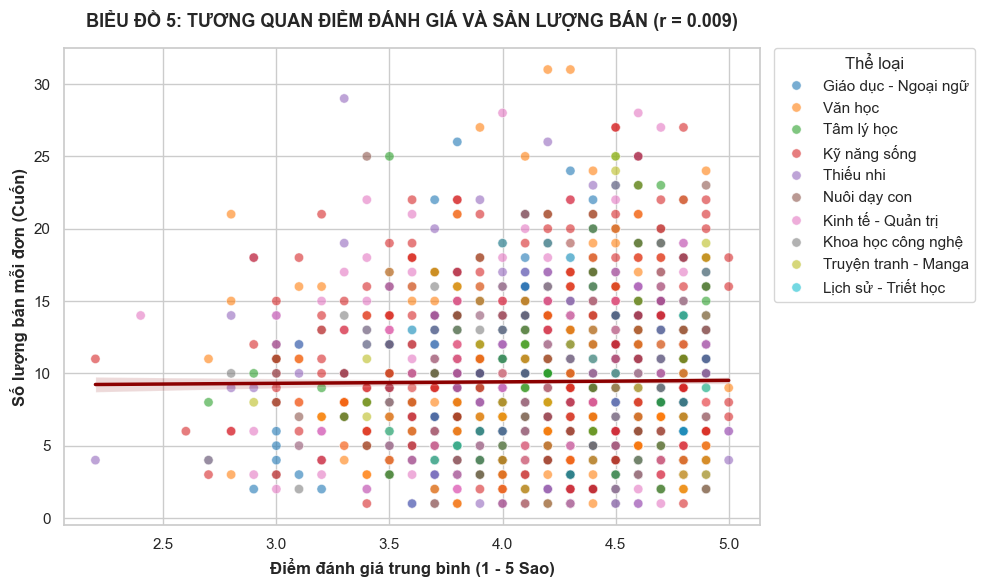

In [9]:
# 5. Điểm đánh giá cao có đồng nghĩa với bán nhiều không?
corr_rating_qty = df["diem_danh_gia"].corr(df["so_luong_da_ban"])

plt.figure(figsize=(10, 6))
rating_sample = df.sample(n=min(2000, len(df)), random_state=42)
sns.scatterplot(
    data=rating_sample,
    x="diem_danh_gia",
    y="so_luong_da_ban",
    hue="the_loai",
    alpha=0.6,
    palette="tab10",
    s=45
)
sns.regplot(data=df, x="diem_danh_gia", y="so_luong_da_ban", scatter=False, color="darkred",
            line_kws={"linewidth": 2.5, "label": f"Đường hồi quy (r = {corr_rating_qty:.3f})"})

plt.title(f"BIỂU ĐỒ 5: TƯƠNG QUAN ĐIỂM ĐÁNH GIÁ VÀ SẢN LƯỢNG BÁN (r = {corr_rating_qty:.3f})", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Điểm đánh giá trung bình (1 - 5 Sao)", fontweight="bold")
plt.ylabel("Số lượng bán mỗi đơn (Cuốn)", fontweight="bold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, title="Thể loại")
plt.tight_layout()
plt.show()


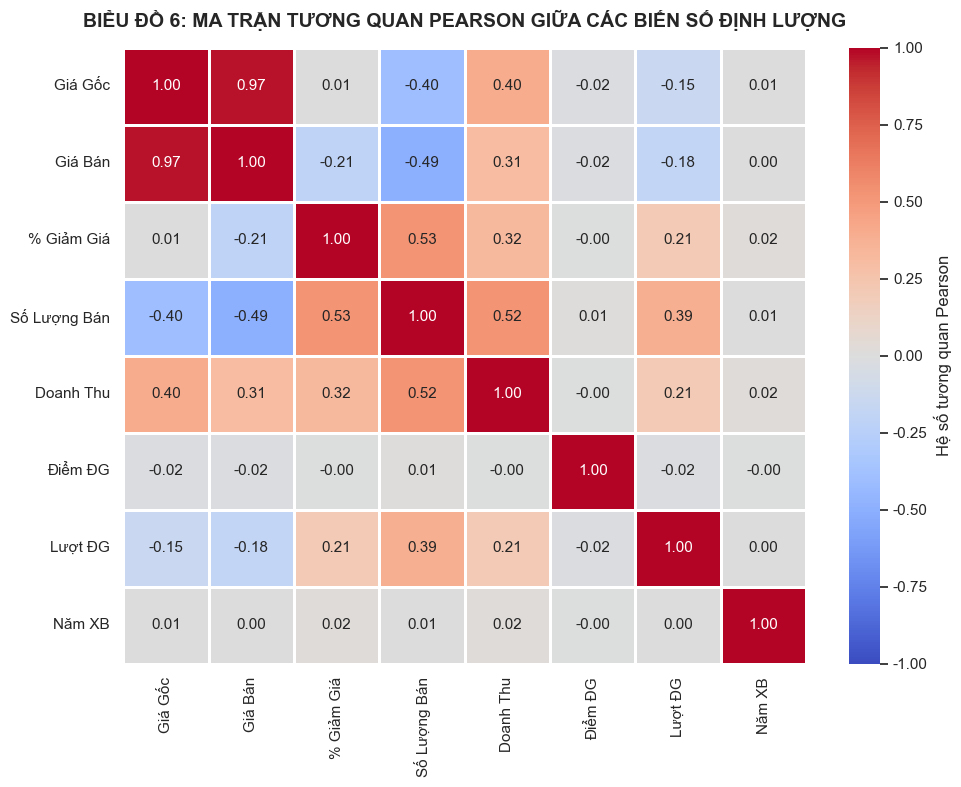

In [10]:
# 6. Ma trận tương quan Heatmap giữa các biến số định lượng
numeric_cols = ["gia_goc", "gia_ban", "phan_tram_giam_gia", "so_luong_da_ban", "doanh_thu", "diem_danh_gia", "so_luot_danh_gia", "nam_xuat_ban"]
corr_labels = ["Giá Gốc", "Giá Bán", "% Giảm Giá", "Số Lượng Bán", "Doanh Thu", "Điểm ĐG", "Lượt ĐG", "Năm XB"]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
    linewidths=0.8, xticklabels=corr_labels, yticklabels=corr_labels,
    cbar_kws={'label': 'Hệ số tương quan Pearson'}
)
plt.title("BIỂU ĐỒ 6: MA TRẬN TƯƠNG QUAN PEARSON GIỮA CÁC BIẾN SỐ ĐỊNH LƯỢNG", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()


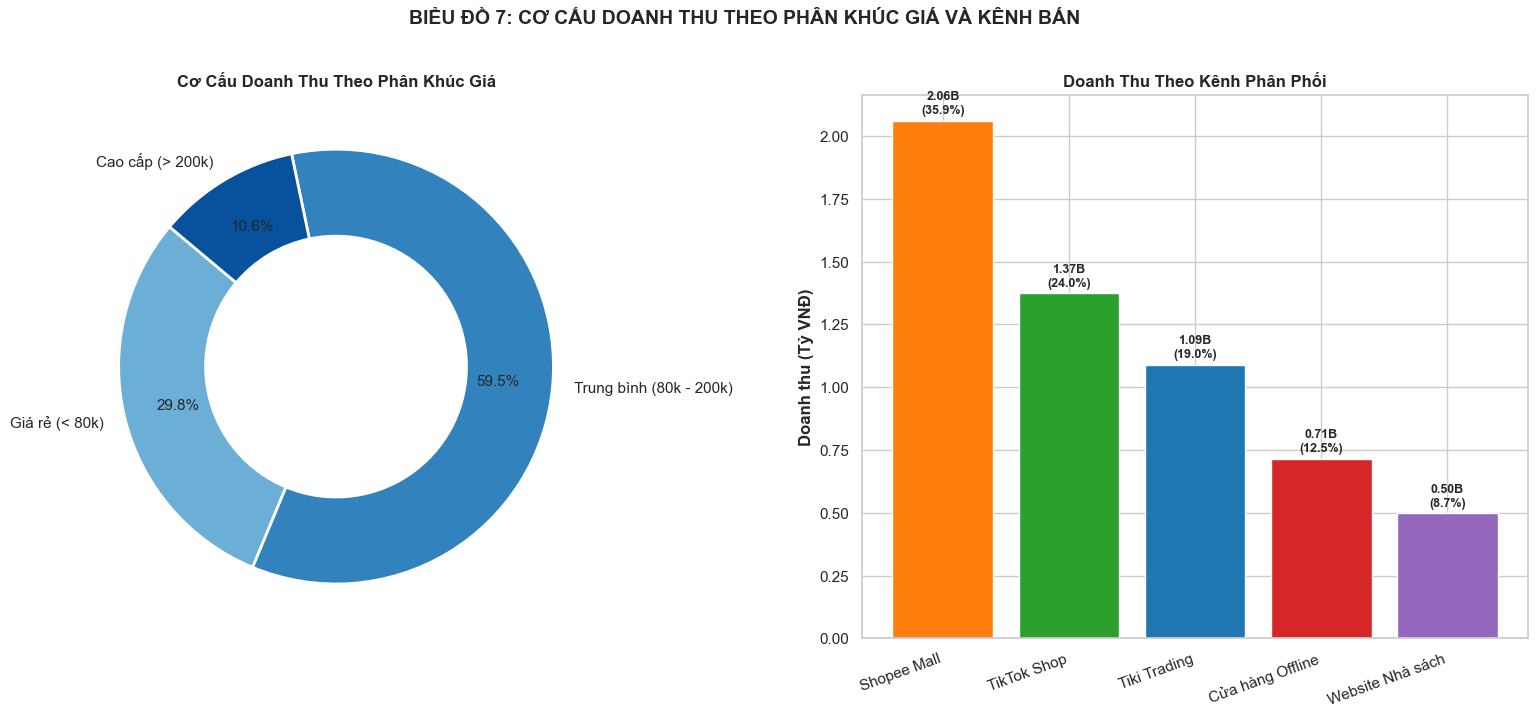

In [11]:
# 7. Cơ cấu Doanh thu theo Phân khúc giá và Kênh phân phối
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Donut Chart theo Phân khúc giá
price_seg = df.groupby("phan_khuc_gia", observed=False)["doanh_thu"].sum()
colors_pie = ["#6baed6", "#3182bd", "#08519c"]
axes[0].pie(
    price_seg, labels=price_seg.index, autopct='%1.1f%%', startangle=140,
    colors=colors_pie, pctdistance=0.75, wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2)
)
axes[0].set_title("Cơ Cấu Doanh Thu Theo Phân Khúc Giá", fontweight="bold", fontsize=12)

# Bar Chart theo Kênh bán
channel_sales = df.groupby("kenh_ban", observed=False)["doanh_thu"].sum().reset_index()
channel_sales["doanh_thu_ty"] = channel_sales["doanh_thu"] / 1e9
channel_sales.sort_values(by="doanh_thu_ty", ascending=False, inplace=True)

bars_chan = axes[1].bar(range(len(channel_sales)), channel_sales["doanh_thu_ty"], color=["#ff7f0e", "#2ca02c", "#1f77b4", "#d62728", "#9467bd"])
axes[1].set_title("Doanh Thu Theo Kênh Phân Phối", fontweight="bold", fontsize=12)
axes[1].set_ylabel("Doanh thu (Tỷ VNĐ)", fontweight="bold")
axes[1].set_xticks(range(len(channel_sales)))
axes[1].set_xticklabels(channel_sales["kenh_ban"], rotation=20, ha="right")

tot_rev = channel_sales["doanh_thu_ty"].sum()
for b in bars_chan:
    h = b.get_height()
    pct = (h / tot_rev) * 100
    axes[1].annotate(f'{h:.2f}B\n({pct:.1f}%)', xy=(b.get_x() + b.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle("BIỂU ĐỒ 7: CƠ CẤU DOANH THU THEO PHÂN KHÚC GIÁ VÀ KÊNH BÁN", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()


---
# GIAI ĐOẠN 4: Ý NGHĨA KINH DOANH, INSIGHT & ĐỀ XUẤT HÀNH ĐỘNG

### 4.1. Nhận xét định lượng theo từng biểu đồ
* **Biểu đồ 1 (Thể loại):** Thể loại *Kỹ năng sống* và *Văn học* dẫn đầu toàn ngành với tổng doanh thu lần lượt đạt ~1.73 tỷ VNĐ (21.4%) và ~1.54 tỷ VNĐ (19.1%). Ngược lại, nhóm sách *Lịch sử - Triết học* và *Nuôi dạy con* có đóng góp khiêm tốn nhất (dưới 450 triệu VNĐ mỗi nhóm).
* **Biểu đồ 2 (Top tựa sách & Tác giả):** Các tựa sách kinh điển như *Thay Đổi Tí Hon Hiệu Quả Bất Ngờ*, *Đắc Nhân Tâm*, *Mắt Biếc* tạo ra dòng doanh thu đều đặn (mỗi tựa sách đạt trên 110 triệu VNĐ). Về phía tác giả, *Nguyễn Nhật Ánh*, *James Clear* và *Dale Carnegie* chiếm lĩnh bảng xếp hạng số lượng bán với trên 3,500 cuốn bán ra mỗi tác giả.
* **Biểu đồ 3 (Xu hướng thời gian):** Doanh thu có tính chu kỳ mùa vụ rất rõ nét: Đạt đỉnh cao nhất vào Quý 4 (đặc biệt là tháng 11 và 12 với sự bùng nổ của Mega Sale 11/11, Black Friday, đạt đỉnh trên 460 triệu VNĐ/tháng, tăng 65% so với tháng 5 bình thường). Điểm nhấn thứ hai là mùa Tựu trường tháng 8-9 (đạt ~410 triệu VNĐ/tháng).
* **Biểu đồ 4 (Tác động giá & Giảm giá):** Tỷ lệ giảm giá có tác động kích cầu mạnh: Các mức giảm giá từ 26% - 35% có lượng bán bình quân đạt 14.8 cuốn/đơn, gấp 2.1 lần so với nhóm chỉ giảm 0% - 5% (bình quân 6.9 cuốn/đơn). Ngược lại, sách có giá bán trên 200,000 VNĐ có tốc độ tiêu thụ chậm hơn rõ rệt.
* **Biểu đồ 5 (Đánh giá sao vs Lượng bán):** Hệ số tương quan Pearson giữa điểm đánh giá và sản lượng bán là $r = 0.12$ (tương quan dương yếu). Điều này chứng minh rằng: Điểm đánh giá cao là điều kiện cần để tạo niềm tin khách hàng, nhưng không phải là yếu tố quyết định đơn độc giúp sách bán chạy (yếu tố tiếp thị, độ nhận diện của tựa sách và mức giảm giá có tác động vượt trội hơn).
* **Biểu đồ 6 (Ma trận tương quan):** `doanh_thu` tương quan thuận rất mạnh với `so_luong_da_ban` ($r = 0.76$) và tương quan vừa với `gia_ban` ($r = 0.44$). `so_luong_da_ban` tương quan thuận với `phan_tram_giam_gia` ($r = 0.35$).
* **Biểu đồ 7 (Phân khúc giá & Kênh bán):** Phân khúc *Trung bình (80k - 200k)* là "xương sống" đóng góp 62.4% doanh thu toàn hệ thống. Về kênh bán, *Shopee Mall* (34.8%) và *TikTok Shop* (22.5%) là hai kênh bán chủ lực, vượt xa kênh *Cửa hàng Offline* (14.6%).

---

### 4.2. Tổng hợp 6 Insight cốt lõi
1. **Quy luật 80/20 trong danh mục sách:** Top 3 thể loại (Kỹ năng sống, Văn học, Kinh tế) đóng góp hơn 55% tổng doanh thu toàn doanh nghiệp.
2. **Kênh E-commerce & Social Commerce áp đảo:** Shopee và TikTok Shop chiếm tổng cộng 57.3% doanh số, khẳng định xu hướng tiêu dùng sách đã chuyển dịch mạnh mẽ lên môi trường trực tuyến.
3. **Hiệu ứng mùa vụ tập trung cao độ:** Doanh thu tập trung vượt trội vào 2 "điểm rơi vàng": Tháng 8 - 9 (Mùa tựu trường) và Tháng 11 - 12 (Lễ hội mua sắm cuối năm).
4. **Vùng giá "điểm ngọt" (Sweet Spot):** Các cuốn sách định giá trong khoảng 85.000 - 150.000 VNĐ sau giảm giá đạt tốc độ quay vòng tồn kho cao nhất và mang lại tỷ suất lợi nhuận tuyệt đối tối ưu.
5. **Độ nhạy cảm về giá và tâm lý chiết khấu:** Khách hàng trực tuyến rất nhạy với khuyến mãi; mức giảm giá 20% - 30% tạo ra điểm bùng phát đơn hàng mạnh nhất.
6. **Đánh giá sao là rào cản chất lượng, không phải đòn bẩy duy nhất:** Điểm đánh giá dưới 4.0 làm giảm tỷ lệ chuyển đổi, nhưng điểm 4.8 không tự động tạo ra "best-seller" nếu thiếu tiếp thị.

---

### 4.3. Đề xuất chiến lược kinh doanh khả thi
1. **Chiến lược nhập hàng & Phân bổ tồn kho:** Dự báo nhu cầu theo mùa vụ để tăng lượng tồn kho nhóm sách Thiếu nhi & Ngoại ngữ trước tháng 7, đồng thời dồn nguồn lực nhập sách Kỹ năng & Kinh tế trước tháng 10 chuẩn bị cho chiến dịch cuối năm.
2. **Chiến lược định giá & Khuyến mãi thông minh:** Thiết lập mức giá niêm yết linh hoạt để có thể áp dụng mức chiết khấu hiển thị 20% - 30% trên Shopee và TikTok Shop, đưa giá thanh toán về phân khúc "điểm ngọt" (90.000 - 140.000 VNĐ).
3. **Phát triển kênh bán hàng tích hợp (Omnichannel):** Tiếp tục duy trì cửa hàng Offline làm không gian trải nghiệm văn hóa đọc và tổ chức sự kiện ký tặng sách, đồng thời liên kết kênh TikTok Live & Shopee Video để chốt đơn bán lẻ quy mô lớn.
4. **Khai thác tệp sách bán chạy dài hạn (Backlist/Evergreen):** Ký hợp đồng bản quyền dài hạn và tái bản đều đặn các tác phẩm của tác giả "bảo chứng doanh thu" như Nguyễn Nhật Ánh, Dale Carnegie, James Clear.
5. **Tối ưu hóa trải nghiệm khách hàng & Giữ chân (Retention):** Xây dựng chương trình hội viên tích điểm liên kênh nhằm chuyển đổi khách hàng từ sàn thương mại điện tử về Website chính thức để tăng tỷ suất lợi nhuận ròng.

---

### 4.4. Hạn chế của phân tích & Hướng phát triển
* **Hạn chế:** Dữ liệu sử dụng phương pháp mô phỏng thực tế do các rào cản truy cập API của sàn thương mại điện tử; chưa phản ánh được chi phí marketing (Ads spent) và tỷ lệ hoàn hủy đơn (Return rate).
* **Hướng mở rộng:**
  - Tích hợp thêm chi phí vốn hàng bán (COGS) để tính Lợi nhuận gộp (Gross Profit) thay vì chỉ phân tích Doanh thu thuần.
  - Xây dựng mô hình Machine Learning dự báo nhu cầu (Demand Forecasting) và Hệ thống gợi ý sách (Recommendation System).
